# Đáp án mã · Bài 7 — RNN, LSTM, GRU

Giải **các bài tập của Bài 7** bằng mã chạy được. Chạy trên CPU; các thí nghiệm seq2seq mất vài chục giây mỗi lần huấn luyện.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from nlpvi import LABELS, load_hard, load_splits, set_seed
from nlpvi.textnn import TextDS, build_vocab, evaluate, fit

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits(); hard = load_hard()
CLASSES = sorted(LABELS); c2i = {c: i for i, c in enumerate(CLASSES)}
itos, stoi = build_vocab(train["text"])
ds_tr, ds_va, ds_hard = (TextDS(d, stoi, c2i) for d in (train, valid, hard))
V = len(itos)

## Bài tập 1 — `input_scale` = 0,1 và 2,0 trong thí nghiệm gradient

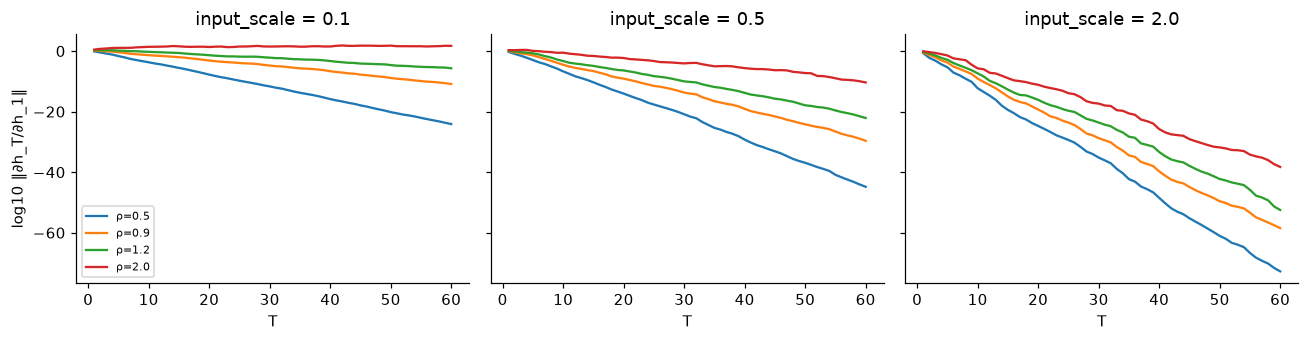

{0.1: np.float64(-2.2), 0.5: np.float64(-10.0), 2.0: np.float64(-23.6)} ← log10 chuẩn gradient sau 30 bước, ρ=1,2


In [2]:
def log_norm_jacobian(rho, T=60, h=32, seed=0, input_scale=0.5):
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(h, h)); W *= rho / np.max(np.abs(np.linalg.eigvals(W)))
    Wx = rng.normal(size=(h, h)) * input_scale
    hs, J, out = np.zeros(h), np.eye(h), []
    for _ in range(T):
        hs = np.tanh(Wx @ rng.normal(size=h) + W @ hs)
        J = (np.diag(1 - hs ** 2) @ W) @ J
        out.append(np.log10(np.linalg.norm(J, 2) + 1e-300))
    return out

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, sc in zip(axes, [0.1, 0.5, 2.0]):
    for rho in [0.5, 0.9, 1.2, 2.0]:
        ax.plot(range(1, 61), log_norm_jacobian(rho, input_scale=sc), label=f"ρ={rho}")
    ax.set_title(f"input_scale = {sc}"); ax.set_xlabel("T")
axes[0].set_ylabel("log10 ‖∂h_T/∂h_1‖"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print({sc: round(log_norm_jacobian(1.2, input_scale=sc)[29], 1) for sc in [0.1, 0.5, 2.0]}, "← log10 chuẩn gradient sau 30 bước, ρ=1,2")

**Đọc kết quả.** Khi `input_scale` **lớn** (2,0) đầu vào đẩy trạng thái vào vùng **bão hòa** của tanh (|h| ≈ 1) nên hệ số $(1-h^2)$ rất nhỏ: gradient **co nhanh hơn** hẳn (≈$10^{-24}$ sau 30 bước). Khi `input_scale` **nhỏ** (0,1) trạng thái gần 0, $1-h^2\approx 1$, và đường cong phụ thuộc chủ yếu vào bán kính phổ ρ: gradient co **chậm hơn nhiều** (≈$10^{-2}$ sau 30 bước ở ρ = 1,2). Bài học: tốc độ biến mất của gradient phụ thuộc cả **trọng số** lẫn **độ lớn đầu vào/trạng thái** — vì vậy chuẩn hóa đầu vào và khởi tạo trọng số quan trọng với RNN.

## Bài tập 2 — Seq2seq với `hidden` = 256

In [3]:
VOC, BOS = 10, 10
class Seq2SeqGRU(nn.Module):
    def __init__(self, d=64, h=128):
        super().__init__()
        self.emb = nn.Embedding(VOC + 1, d)
        self.enc = nn.GRU(d, h, batch_first=True); self.dec = nn.GRU(d, h, batch_first=True)
        self.out = nn.Linear(h, VOC)
    def forward(self, x, y_in):
        _, h = self.enc(self.emb(x)); o, _ = self.dec(self.emb(y_in), h); return self.out(o)
    @torch.no_grad()
    def doc_thang(self, x):
        _, h = self.enc(self.emb(x)); y = torch.full((x.size(0), 1), BOS); outs = []
        for _ in range(x.size(1)):
            o, h = self.dec(self.emb(y), h); y = self.out(o[:, -1]).argmax(-1, keepdim=True); outs.append(y)
        return torch.cat(outs, 1)

def lay_batch(B, L, g):
    x = torch.randint(0, 10, (B, L), generator=g); y = x.flip(1)
    return x, y, torch.cat([torch.full((B, 1), BOS), y[:, :-1]], 1)

def huan_luyen(model, steps=3000, seed=0):
    set_seed(seed); g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        L = int(torch.randint(3, 17, (1,), generator=g))
        x, y, y_in = lay_batch(64, L, g)
        loss = F.cross_entropy(model(x, y_in).reshape(-1, VOC), y.reshape(-1))
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()

def acc_theo_do_dai(model, lengths=(4, 8, 12, 16, 20), n=400, seed=123):
    g = torch.Generator().manual_seed(seed); model.eval(); res = {}
    for L in lengths:
        x, y, _ = lay_batch(n, L, g); res[f"L={L}"] = round((model.doc_thang(x) == y).all(1).float().mean().item(), 3)
    return res

kq = {}
for h in [128, 256]:
    t0 = time.time(); m = Seq2SeqGRU(h=h); huan_luyen(m)
    kq[f"hidden={h}"] = acc_theo_do_dai(m)
    print(f"hidden={h}: {time.time() - t0:.0f}s")
pd.DataFrame(kq).T

hidden=128: 191s


hidden=256: 171s


,L=4,L=8,L=12,L=16,L=20
hidden=128,0.998,0.938,0.482,0.040,0.0
hidden=256,1.000,0.945,0.575,0.058,0.0


**Đọc kết quả.** Hidden lớn hơn chứa được nhiều thông tin hơn nên ngưỡng độ dài mà độ chính xác bắt đầu tụt **dịch sang phải** (và có thể học lâu hơn), nhưng **nút thắt không biến mất**, chỉ rộng ra: vẫn tụt mạnh ở độ dài lớn và ở độ dài ngoài phạm vi huấn luyện (L=20). Muốn giải quyết gốc rễ cần attention (Bài 8).

## Bài tập 3 — Encoder hai chiều

In [4]:
class Seq2SeqBi(Seq2SeqGRU):
    def __init__(self, d=64, h=128):
        super().__init__(d, h)
        self.enc = nn.GRU(d, h, batch_first=True, bidirectional=True)
        self.noi = nn.Linear(2 * h, h)                          # nối hai trạng thái cuối → khởi tạo decoder
    def _init(self, x):
        _, h = self.enc(self.emb(x))
        return torch.tanh(self.noi(torch.cat([h[0], h[1]], -1))).unsqueeze(0)
    def forward(self, x, y_in):
        o, _ = self.dec(self.emb(y_in), self._init(x)); return self.out(o)
    @torch.no_grad()
    def doc_thang(self, x):
        h = self._init(x); y = torch.full((x.size(0), 1), BOS); outs = []
        for _ in range(x.size(1)):
            o, h = self.dec(self.emb(y), h); y = self.out(o[:, -1]).argmax(-1, keepdim=True); outs.append(y)
        return torch.cat(outs, 1)

t0 = time.time(); mb = Seq2SeqBi(); huan_luyen(mb)
print(f"{time.time() - t0:.0f}s")
pd.DataFrame({"GRU một chiều (h=128)": kq["hidden=128"], "GRU hai chiều + nối": acc_theo_do_dai(mb)}).T

178s


,L=4,L=8,L=12,L=16,L=20
GRU một chiều (h=128),0.998,0.938,0.482,0.040,0.0
GRU hai chiều + nối,1.000,0.827,0.198,0.005,0.0


**Đọc kết quả — ngược với dự đoán ban đầu.** Encoder hai chiều **không** giúp mà còn **tệ hơn** trong cùng ngân sách 3.000 bước: độ chính xác ở L=8 là ≈0,83 (so với ≈0,94 của GRU một chiều) và ở L=12 chỉ ≈0,20 (so với ≈0,48). Có hai lý do hợp lý: (1) ta thêm tham số (lớp nối `2h → h`) và độ phức tạp tối ưu hóa trong khi **nút thắt không đổi** — toàn bộ nguồn vẫn bị nén vào *một* vector; (2) với bài toán đảo, trạng thái xuôi cuối vốn đã chứa các phần tử *cuối* (cái decoder cần ra *đầu tiên*), nên trạng thái ngược không bổ sung nhiều, còn việc học cách nối hai trạng thái làm huấn luyện chậm hơn. Đây là một **kết quả đơn seed**, nhưng chênh lệch lớn; bài học là *thêm độ phức tạp không tự động giúp* nếu không động tới nguyên nhân gốc (nút thắt). Muốn thật sự cải thiện cần attention (Bài 8).

## Bài tập 4 — Bỏ `pack_padded_sequence`

In [5]:
class RNNPhanLoai(nn.Module):
    def __init__(self, V, kieu="lstm", d=64, h=64, n_cls=3, p=0.4, bidirectional=True, pack=True, pool="max"):
        super().__init__()
        self.pack, self.pool, self.bi = pack, pool, bidirectional
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.rnn = {"lstm": nn.LSTM, "gru": nn.GRU}[kieu](d, h, batch_first=True, bidirectional=bidirectional)
        self.drop = nn.Dropout(p); self.fc = nn.Linear((2 if bidirectional else 1) * h, n_cls)
    def forward(self, x):
        mask = x != 0; L = x.size(1); e = self.emb(x)
        if self.pack:
            lengths = mask.sum(1).clamp(min=1).cpu()
            out, hid = self.rnn(pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False))
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=L)
        else:
            out, hid = self.rnn(e)
        if self.pool == "last":
            # Trạng thái ẩn CUỐI do RNN trả về (h_n). Với pack, đó là trạng thái sau token THẬT cuối cùng của mỗi câu;
            # không pack thì là trạng thái sau khi đã đi qua cả các ô đệm.
            h = hid[0] if isinstance(hid, tuple) else hid                    # LSTM trả về (h, c)
            return self.fc(self.drop(torch.cat([h[-2], h[-1]], -1) if self.bi else h[-1]))
        out = out.masked_fill(~mask.unsqueeze(-1), -1e9)
        return self.fc(self.drop(out.max(1).values))

def chay(**kw):
    v, h = [], []
    for sd in [0, 1, 2]:
        set_seed(sd); m = RNNPhanLoai(V, **kw); fit(m, ds_tr, ds_va, seed=sd, clip=1.0)
        v.append(evaluate(m, ds_va)[1]); h.append(evaluate(m, ds_hard)[1])
    return f"{np.mean(v):.3f} ± {np.std(v):.3f}", f"{np.mean(h):.3f} ± {np.std(h):.3f}"

rows = []
for ten, kw in [("BiLSTM + pack + max-pool (Bài 7)", dict(pack=True)), ("BiLSTM, KHÔNG pack + max-pool có mặt nạ", dict(pack=False)),
                ("LSTM một chiều, pack, trạng thái CUỐI", dict(bidirectional=False, pack=True, pool="last")),
                ("LSTM một chiều, KHÔNG pack, trạng thái CUỐI", dict(bidirectional=False, pack=False, pool="last"))]:
    v, h = chay(**kw); rows.append({"cấu hình": ten, "valid": v, "câu khó": h})
pd.DataFrame(rows).set_index("cấu hình")

,valid,câu khó
cấu hình,,
BiLSTM + pack + max-pool (Bài 7),0.932 ± 0.006,0.566 ± 0.012
"BiLSTM, KHÔNG pack + max-pool có mặt nạ",0.931 ± 0.007,0.488 ± 0.048
"LSTM một chiều, pack, trạng thái CUỐI",0.929 ± 0.009,0.517 ± 0.012
"LSTM một chiều, KHÔNG pack, trạng thái CUỐI",0.917 ± 0.007,0.499 ± 0.041


**Đọc kết quả (3 seed).** `pack_padded_sequence` **không bao giờ tệ hơn** trong cả bốn so sánh, nhưng **chênh lệch nhỏ**: với BiLSTM + max-pooling có mặt nạ, valid gần như bằng nhau (≈0,932 so với ≈0,931) vì ô đệm đã bị loại khỏi bước gộp; với **LSTM một chiều lấy trạng thái cuối**, bỏ pack giảm valid từ ≈0,929 xuống ≈0,917 (khoảng 1,5 lần độ lệch chuẩn) — đúng cơ chế đã dự đoán: trạng thái cuối của câu ngắn phải "trôi" qua một chuỗi ô đệm (toàn vector 0) trước khi được đọc, nên bị pha loãng. Trên 40 câu khó, độ lệch chuẩn (≈0,04–0,05) lớn hơn chênh lệch nên không kết luận được. Quy tắc: **nếu dùng trạng thái cuối, hãy pack**; nếu gộp theo thời gian có mặt nạ, tác động nhỏ hơn nhưng pack vẫn là thói quen đúng.

> **Một bài học về gỡ lỗi.** Phiên bản đầu của đáp án này lấy trạng thái cuối bằng `out[:, -1]` *sau* `pad_packed_sequence` và cho macro-F1 chỉ ≈0,23 (ngang đoán lớp phổ biến). Đó **không phải hiện tượng thật**: `pad_packed_sequence` đệm lại bằng số 0, nên `out[:, -1]` là vector 0 với mọi câu ngắn hơn độ dài tối đa. Cách đúng là dùng trạng thái ẩn cuối `h_n` do RNN trả về (như trong mã trên). Khi một kết quả bất thường *quá tệ*, hãy nghi ngờ **mã của mình** trước khi tìm lời giải thích cho "hiện tượng".

## Bài tập 5 (khó) — LSTM cell bằng NumPy so với `nn.LSTMCell`

In [6]:
def sigmoid(z): return 1 / (1 + np.exp(-z))

def lstm_cell_numpy(x, h, c, W_ih, W_hh, b_ih, b_hh):
    gates = W_ih @ x + b_ih + W_hh @ h + b_hh
    i, f, g, o = np.split(gates, 4)                      # thứ tự cổng của PyTorch: i, f, g, o
    i, f, o, g = sigmoid(i), sigmoid(f), sigmoid(o), np.tanh(g)
    c_moi = f * c + i * g
    h_moi = o * np.tanh(c_moi)
    return h_moi, c_moi

set_seed(0)
cell = nn.LSTMCell(6, 5)
x, h0, c0 = torch.randn(6), torch.randn(5), torch.randn(5)
h_t, c_t = cell(x[None], (h0[None], c0[None]))
W_ih, W_hh, b_ih, b_hh = [p.detach().numpy() for p in (cell.weight_ih, cell.weight_hh, cell.bias_ih, cell.bias_hh)]
h_n, c_n = lstm_cell_numpy(x.numpy(), h0.numpy(), c0.numpy(), W_ih, W_hh, b_ih, b_hh)
print("h khớp PyTorch:", np.allclose(h_n, h_t[0].detach().numpy(), atol=1e-6), "| c khớp:", np.allclose(c_n, c_t[0].detach().numpy(), atol=1e-6))
print("sai lệch lớn nhất:", float(np.abs(h_n - h_t[0].detach().numpy()).max()))

h khớp PyTorch: True | c khớp: True
sai lệch lớn nhất: 5.960464477539063e-08


**Đọc kết quả.** Hai bản trùng khớp đến sai số số học. Chú ý hai điểm hay sai: (1) **thứ tự cổng** trong trọng số gộp của PyTorch là `i, f, g, o` (nhập, quên, ứng viên, xuất); (2) PyTorch có **hai** vector bias (`bias_ih` và `bias_hh`) cộng lại. Ô nhớ cập nhật `c' = f·c + i·g` là phép **cộng có cổng** — chính đường đi này giữ gradient không bị nhân với một ma trận ở mỗi bước (Bài 7, mục 4).